# Introduction

## 1. Project Overview

We chose to look at **hotel booking cancellations**. Hotels lose money when a booked room is cancelled and left empty, so many hotels *overbook*, selling more rooms than they have and expecting some guests to cancel. If they overbook too much, guests turn up to find no room and have to be sent to another hotel at the hotel's expense. Predicting which bookings will be cancelled helps a hotel get this balance right.

Our question is therefore: **given the details of a booking, can we predict whether it will be cancelled?**

We use the [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) dataset from Kaggle, originally published by [Antonio, de Almeida & Nunes (2019)](https://doi.org/10.1016/j.dib.2018.11.126). It suits the project because:

* the target, `is_canceled`, is binary;
* it is real business data from two hotels in Portugal, a city hotel and a resort hotel;
* it covers more than two years, so we can test whether a model trained on the past predicts the future.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Our Data

Each group member downloads `hotel_bookings.csv` from [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) and saves it in the same folder as this notebook.

In [2]:
hotels = pd.read_csv("hotel_bookings.csv")
print(f"{hotels.shape[0]:,} bookings, {hotels.shape[1]} columns")
hotels.head()

119,390 bookings, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Each row is one booking due to arrive between July 2015 and August 2017. The main columns are:

* **`is_canceled`** (target): 1 if the booking was cancelled, 0 if the guest arrived.
* **`hotel`**: City Hotel or Resort Hotel.
* **`lead_time`**: days between making the booking and the arrival date.
* **Arrival date**: `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month`.
* **Stay and guests**: `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children`, `babies`, `meal`.
* **How it was booked**: `market_segment`, `distribution_channel`, `agent`, `company`, `customer_type`, `deposit_type`.
* **Customer history**: `country`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`.
* **Price**: `adr`, the average daily rate (price per night, in euros).
* **Recorded later**: `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list` and `required_car_parking_spaces`. These are only known after the booking was made (for example, none of the 7,416 bookings with a parking space was cancelled, which suggests parking is recorded on arrival). Using them would mean predicting with information from the future, so we remove them in `02-Preprocessing`.

## 3. Exploratory Data Analysis

### 3.1 Overview

`info` shows each column's type and number of non-missing values. Only `children`, `country`, `agent` and `company` have missing values; we deal with these in `02-Preprocessing`.

In [3]:
hotels.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
hotels.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


### 3.2 The target variable

37% of bookings were cancelled, so the classes are fairly balanced. The city hotel cancels far more often (42%) than the resort hotel (28%).

hotel
City Hotel      0.417
Resort Hotel    0.278
Name: is_canceled, dtype: float64


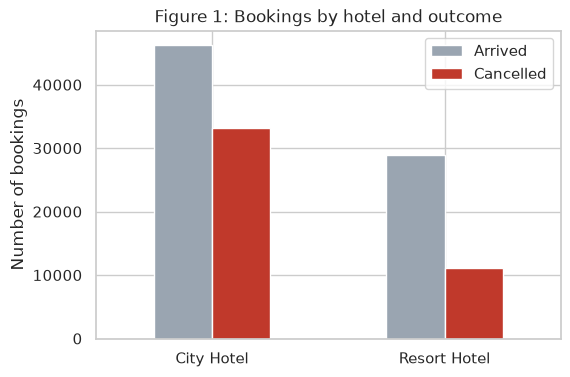

In [5]:
print(hotels.groupby("hotel")["is_canceled"].mean().round(3))

counts = hotels.groupby(["hotel", "is_canceled"]).size().unstack()
counts.columns = ["Arrived", "Cancelled"]
ax = counts.plot(kind="bar", rot=0, color=["#9aa5b1", "#c0392b"], figsize=(6, 4))
ax.set_xlabel("")
ax.set_ylabel("Number of bookings")
ax.set_title("Figure 1: Bookings by hotel and outcome")
plt.show()

### 3.3 Lead time

Bookings made far in advance are much more likely to be cancelled. The relationship is non-linear: it rises steeply over the first few months, then levels off.

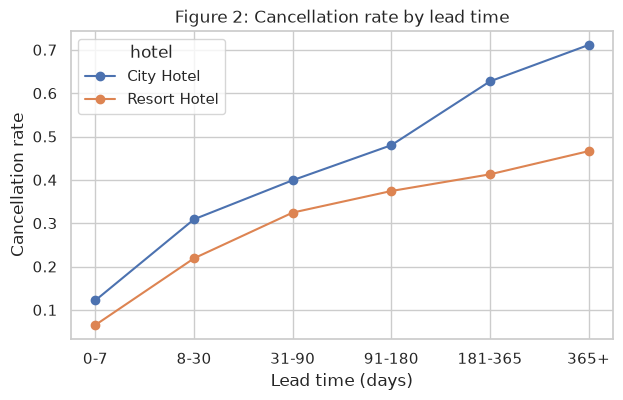

In [6]:
bands = pd.cut(hotels["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
               labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
rate = hotels.groupby([bands, "hotel"], observed=True)["is_canceled"].mean().unstack()

ax = rate.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Cancellation rate")
ax.set_title("Figure 2: Cancellation rate by lead time")
plt.show()

### 3.4 How the booking was made

The cancellation rate varies a lot between categories:

* **Deposit type**: almost every non-refundable booking was cancelled. This is surprising, and may reflect how group or tour-operator bookings were recorded. We keep an eye on it.
* **Market segment**: group bookings cancel most often, direct and corporate bookings least.
* **Customer type**: transient (individual) bookings cancel more than group or contract bookings.

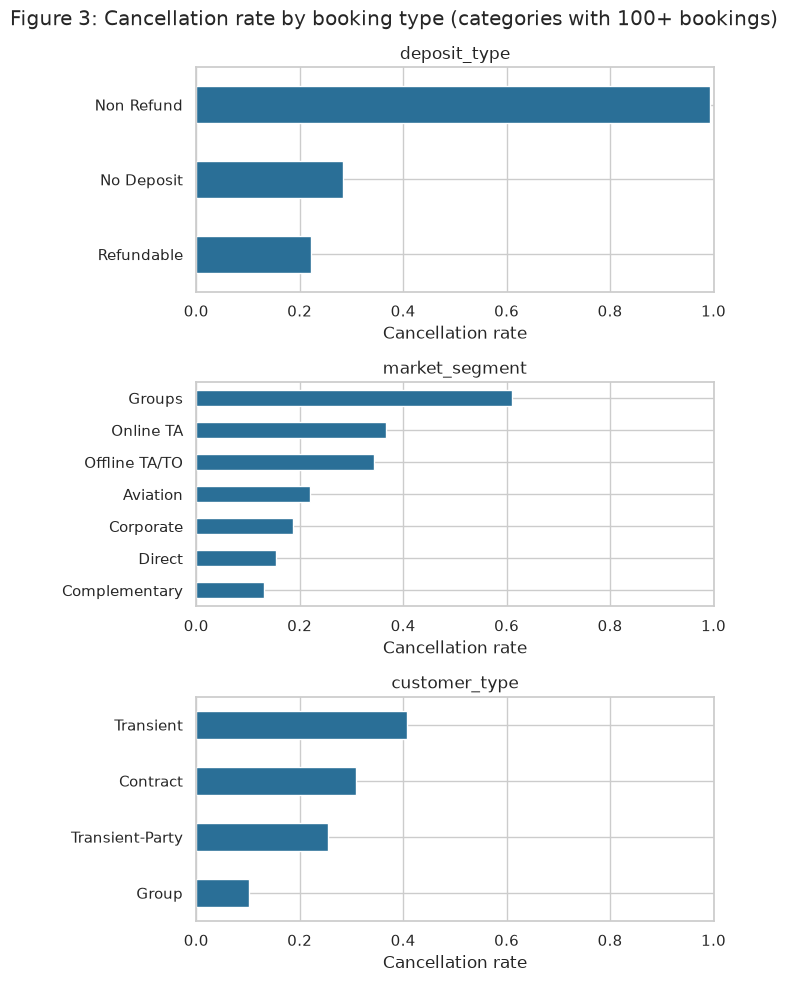

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(7, 10))
for ax, col in zip(axes, ["deposit_type", "market_segment", "customer_type"]):
    stats = hotels.groupby(col)["is_canceled"].agg(["mean", "size"])
    rate = stats.loc[stats["size"] >= 100, "mean"].sort_values()   # hide tiny categories
    rate.plot(kind="barh", ax=ax, color="#2a6f97")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Cancellation rate")
    ax.set_ylabel("")
    ax.set_title(col)
fig.suptitle("Figure 3: Cancellation rate by booking type (categories with 100+ bookings)")
plt.tight_layout()
plt.show()

### 3.5 Customer history and country

Guests who have cancelled before usually cancel again, while repeat guests rarely cancel. Bookings from Portugal, the hotels' home country, are cancelled much more often than bookings from abroad.

Cancellation rate if previously cancelled: 0.916
Cancellation rate for repeat guests:       0.145


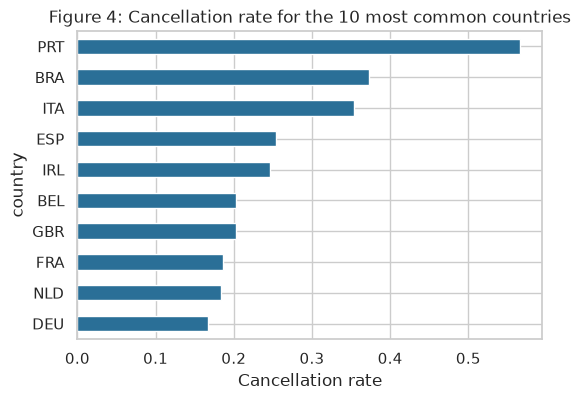

In [8]:
print("Cancellation rate if previously cancelled:",
      round(hotels.loc[hotels.previous_cancellations > 0, "is_canceled"].mean(), 3))
print("Cancellation rate for repeat guests:      ",
      round(hotels.loc[hotels.is_repeated_guest == 1, "is_canceled"].mean(), 3))

top10 = hotels["country"].value_counts().head(10).index
rate = hotels[hotels.country.isin(top10)].groupby("country")["is_canceled"].mean().sort_values()
ax = rate.plot(kind="barh", color="#2a6f97", figsize=(6, 4))
ax.set_xlabel("Cancellation rate")
ax.set_title("Figure 4: Cancellation rate for the 10 most common countries")
plt.show()

### 3.6 Seasonality

Cancellation rates change through the year, and differ between 2015, 2016 and 2017. This suggests that a model trained on one period may not predict a later period perfectly, which we consider when choosing our train/test split.

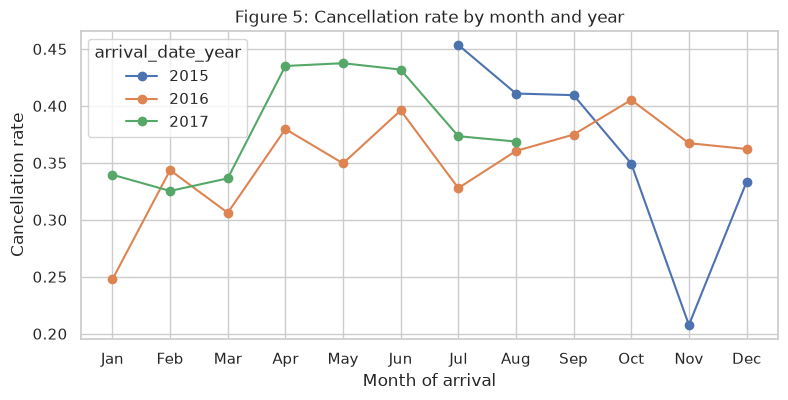

In [9]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
rate = hotels.groupby(["arrival_date_month", "arrival_date_year"])["is_canceled"].mean().unstack()
ax = rate.reindex(months).plot(marker="o", figsize=(9, 4))
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in months])
ax.set_xlabel("Month of arrival")
ax.set_ylabel("Cancellation rate")
ax.set_title("Figure 5: Cancellation rate by month and year")
plt.show()

### 3.7 Correlations

The heatmap shows correlations between the numerical columns. `lead_time` has the strongest positive correlation with cancellation, and `total_of_special_requests` the strongest negative one (`required_car_parking_spaces` is close behind, but it is one of the columns recorded after booking). No single feature is strongly correlated on its own, which suggests models that combine many features will do best.

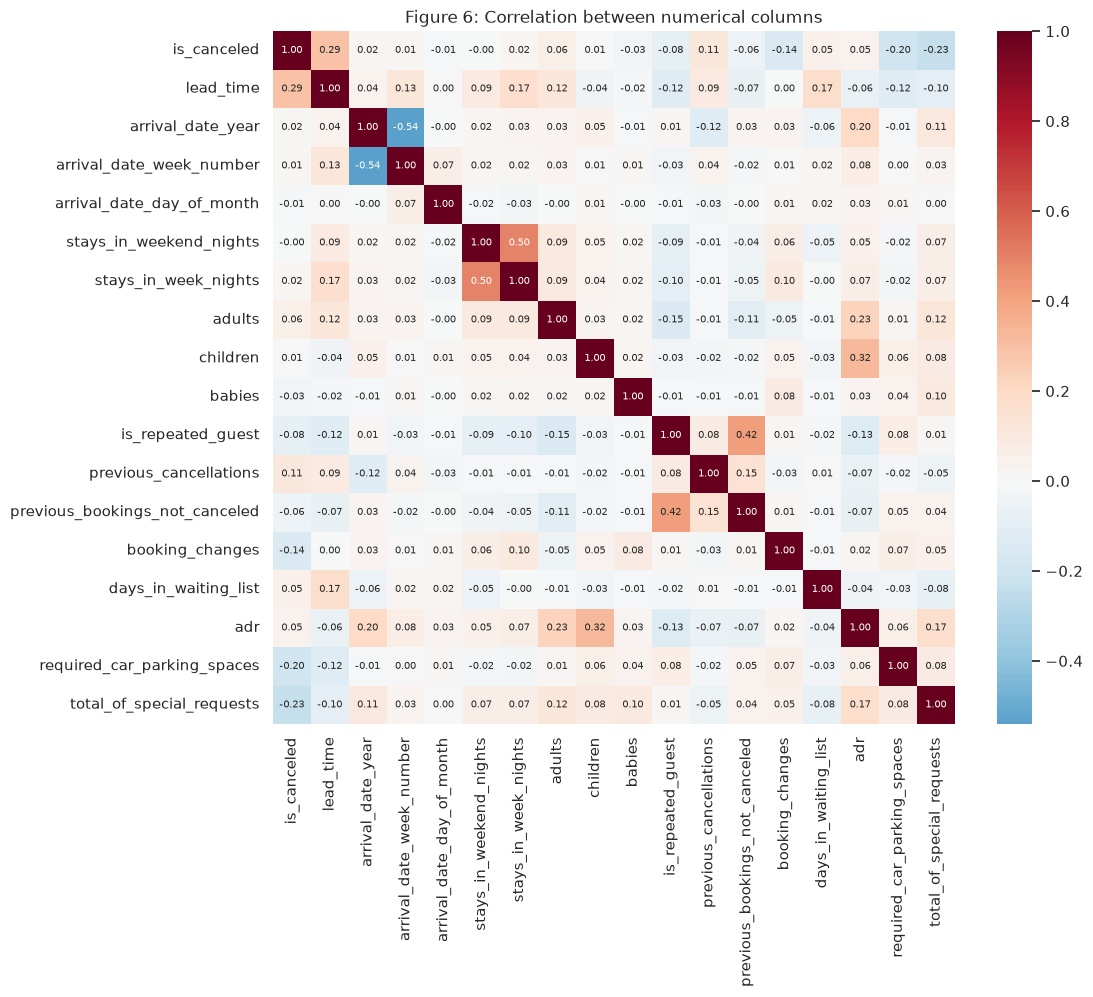

In [10]:
corr = hotels.select_dtypes("number").drop(columns=["agent", "company"]).corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Figure 6: Correlation between numerical columns")
plt.show()

## 4. Summary

The features that look most useful for predicting cancellation are:

* `lead_time` (strong, non-linear effect)
* `deposit_type`, `market_segment` and `customer_type`
* `previous_cancellations` and `is_repeated_guest`
* `country`
* `total_of_special_requests`
* the arrival month, and which `hotel` the booking is for

In `02-Preprocessing` we handle missing values, remove the columns that are only known after booking, encode the categorical features and create the train/test split.

## References

* Antonio, N., de Almeida, A. and Nunes, L. (2019). [Hotel booking demand datasets](https://doi.org/10.1016/j.dib.2018.11.126). *Data in Brief*, 22, 41–49.
* Mostipak, J. (2020). [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand). Kaggle.